# XGBoost: input ranking and data-driven family merging

**Input:** `features_with_folds.csv` from the m* calibration notebook (or `mstar_calibration.zip`).

**Part A: rank the 6 inputs.** XGBoost learns the **residual** ΔS = \|S\| − S_SPB(family m*). Everything happens
**inside the training folds**: m* is refitted on the training papers of each fold, then the model is trained, then it is
scored on the held-out papers. This is repeated over every seed × fold, and each input is ranked three ways:

| Method | Question it answers |
|---|---|
| **Drop-column** (main) | How much worse is the test MAE when the model is retrained *without* this input? Robust to correlated inputs. |
| Permutation | How much worse is the test MAE when this input is shuffled in the test papers? Underestimates correlated inputs. |
| SHAP (mean \|contribution\|) | How much does this input move the predictions on the test papers? |

**Part B: merge families by XGBoost transferability.** For each pair of families (A, B): a model trained on A predicts
B's residuals. If that's about as good as B's *own* model (cross-validated by paper), A and B have the **same kind of
deviation from SPB**, so they can share one residual model. The pairwise distances are clustered hierarchically →
a **merge tree**. The merge is then **validated without leakage** (nested: the tree is rebuilt on each outer training set)
against per-family models, one pooled model and the calibrated SPB alone.

The grouping is for the **residual model only**. m* stays family-specific, because it was calibrated per family.

## 0. Settings

In [1]:
INPUT = "features_with_folds.csv"      # or "mstar_calibration.zip"; you'll be asked to upload if missing
OUT_DIR = "xgb_ranking_merging"
INPUTS = ["T_K", "log10_n_cm3", "S_SPB", "el_X_mean", "el_n_valence_mean", "dopant_total_frac"]
#   S_SPB = the SPB baseline with family m* refitted inside each training fold (not the m* = 1 column)
EXCLUDE_FAMILIES = []                  # e.g. ["Marcasite FeSb2"]: SPB not applicable (m* hit the search limit)
RANK_SEEDS = None                      # None = all repeat seeds in the file; or e.g. [42]
MIN_TRAIN_PAPERS = 3                   # family m*: needs >= this many training papers, else overall m*
M_BOUNDS = (0.05, 20.0)

XGB_PARAMS = dict(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                  min_child_weight=5, reg_lambda=1.0, tree_method="hist", random_state=0, n_jobs=-1)
XGB_SMALL = dict(XGB_PARAMS, n_estimators=200, max_depth=3)   # for the many small per-family models in Part B
PERM_REPEATS = 3

# Part B
MIN_GROUP_PAPERS = 4                   # a group needs >= this many papers (and points) to enter the merge tree
MIN_GROUP_POINTS = 30
SELF_FOLDS = 3                         # paper-grouped CV inside a group for its "own-model" reference error
MERGE_THRESHOLD = 0.25                 # merge when symmetric transfer penalty <= 25 % above own-model error
NESTED = True                          # leakage-free validation of the merge (primary split); takes a few minutes

In [2]:
import json, zipfile, hashlib, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.path import Path as MPath
from scipy.integrate import quad
from scipy.special import expit
from scipy.optimize import minimize_scalar
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform
import xgboost as xgb
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 70)
OUT = Path(OUT_DIR); OUT.mkdir(exist_ok=True)

# palette (validated reference palette; categorical slots in fixed order, neutral for unmerged)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
NEUTRAL, INK, INK2, GRID = "#b4b2ac", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

## 1. Load

In [3]:
p = Path(INPUT)
if not p.exists():
    try:
        from google.colab import files
        p = Path(next(iter(files.upload())))
    except ImportError:
        raise FileNotFoundError(INPUT)
if p.suffix == ".zip":
    with zipfile.ZipFile(p) as z:
        z.extract("features_with_folds.csv", "."); p = Path("features_with_folds.csv")
d = pd.read_csv(p, low_memory=False)
d = d[~d["family"].isin(EXCLUDE_FAMILIES)].reset_index(drop=True)
d["n_m3"] = 10 ** d["log10_n_cm3"] * 1e6
d["w"] = 1.0 / d.groupby("sample_key")["sample_key"].transform("size")      # every sample counts equally
SEEDS = [int(c[6:]) for c in d.columns if c.startswith("fold_s")]
RANK_SEEDS = RANK_SEEDS or SEEDS
print(d.shape, "|", d.sample_key.nunique(), "samples |", d.SID.nunique(), "papers | repeat seeds:", SEEDS,
      "| excluded:", EXCLUDE_FAMILIES or "none")

Saving mstar_calibration (3).zip to mstar_calibration (3).zip
(8358, 47) | 982 samples | 263 papers | repeat seeds: [42, 7, 123, 2024, 31415] | excluded: none


## 2. SPB baseline and m* calibration (same functions as the m* notebook)

In [4]:
KB, H_PL, M_E, E_CH = 1.380649e-23, 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19
_eta = np.linspace(-30, 100, 2601)
_F = lambda j, e: quad(lambda x: x**j * expit(e - x), 0, max(e, 0) + 60, limit=200)[0]
_F12 = np.array([_F(0.5, e) for e in _eta]); _F1 = np.array([_F(1.0, e) for e in _eta]); _F0 = np.logaddexp(0, _eta)

def spb_seebeck_abs_uVK(n_m3, T_K, m_star=1.0):
    n_m3, T_K = np.asarray(n_m3, float), np.asarray(T_K, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        F12 = n_m3 / (4 * np.pi * (2 * m_star * M_E * KB * T_K / H_PL**2) ** 1.5)
        eta = np.interp(np.log(F12), np.log(_F12), _eta)
        lo, hi = F12 < _F12[0], F12 > _F12[-1]
        eta = np.where(lo, np.log(F12 * 2 / np.sqrt(np.pi)), eta)
        e_hi = (1.5 * F12) ** (2 / 3); e_hi = (1.5 * F12 / (1 + np.pi**2 / (8 * e_hi**2))) ** (2 / 3)
        eta = np.where(hi, e_hi, eta)
        S = np.where(lo, 2 - eta, np.where(hi, np.pi**2 / (3 * eta),
                     2 * np.interp(eta, _eta, _F1) / np.interp(eta, _eta, _F0) - eta))
    return S * KB / E_CH * 1e6

def fit_mstar(g):
    w = g["w"].to_numpy(); S, n, T = g["S_abs_uVK"].to_numpy(), g["n_m3"].to_numpy(), g["T_K"].to_numpy()
    loss = lambda lm: np.sum(w * np.abs(S - spb_seebeck_abs_uVK(n, T, np.exp(lm)))) / w.sum()
    return float(np.exp(minimize_scalar(loss, bounds=np.log(M_BOUNDS), method="bounded", options={"xatol": 1e-4}).x))

def calibrate(train, *others):
    """Fit family m* on `train` only; return S_SPB for train and every other frame."""
    m_glob = fit_mstar(train)
    fam = {f: fit_mstar(g) for f, g in train.groupby("family") if g["SID"].nunique() >= MIN_TRAIN_PAPERS}
    out = []
    for df in (train,) + others:
        m = df["family"].map(fam).fillna(m_glob).to_numpy()
        out.append(spb_seebeck_abs_uVK(df["n_m3"], df["T_K"], m))
    return out

def splits_from(fold_col):
    fold_col = np.asarray(fold_col)
    return [(np.where(fold_col != k)[0], np.where(fold_col == k)[0]) for k in sorted(np.unique(fold_col))]

def mae(a, b, w=None): return float(np.average(np.abs(np.asarray(a) - np.asarray(b)), weights=w))
def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

def xgb_fit(X, y, w, params=XGB_PARAMS):
    return xgb.XGBRegressor(**params).fit(X, y, sample_weight=w)

## Part A: rank the 6 inputs (inside the training folds, all seeds × folds)

In [5]:
t0 = time.time()
imp_rows, score_rows = [], []
for sd in RANK_SEEDS:
    for k, (tr, te) in enumerate(splits_from(d[f"fold_s{sd}"])):
        train, test = d.iloc[tr].copy(), d.iloc[te].copy()
        train["S_SPB"], test["S_SPB"] = calibrate(train, test)
        ytr = train.S_abs_uVK - train.S_SPB; yte = test.S_abs_uVK - test.S_SPB
        full = xgb_fit(train[INPUTS], ytr, train.w)
        pred = full.predict(test[INPUTS]); base = mae(yte, pred)
        direct = xgb_fit(train[[c for c in INPUTS if c != "S_SPB"]], train.S_abs_uVK, train.w)
        score_rows.append({"seed": sd, "fold": k,
                           "MAE_SPB_cal": mae(test.S_abs_uVK, test.S_SPB), "MAE_SPB+XGB": mae(test.S_abs_uVK, test.S_SPB + pred),
                           "MAE_XGB_direct": mae(test.S_abs_uVK, direct.predict(test[[c for c in INPUTS if c != "S_SPB"]])),
                           "RMSE_SPB_cal": rmse(test.S_abs_uVK, test.S_SPB), "RMSE_SPB+XGB": rmse(test.S_abs_uVK, test.S_SPB + pred)})
        contrib = full.get_booster().predict(xgb.DMatrix(test[INPUTS]), pred_contribs=True)[:, :-1]
        gain = full.get_booster().get_score(importance_type="gain"); gsum = sum(gain.values()) or 1
        rng = np.random.default_rng(1000 * sd + k)
        for j, f in enumerate(INPUTS):
            drop = xgb_fit(train[[c for c in INPUTS if c != f]], ytr, train.w)
            d_drop = mae(yte, drop.predict(test[[c for c in INPUTS if c != f]])) - base
            perm = []
            for _ in range(PERM_REPEATS):
                Xp = test[INPUTS].copy(); Xp[f] = rng.permutation(Xp[f].to_numpy())
                perm.append(mae(yte, full.predict(Xp)) - base)
            imp_rows.append({"seed": sd, "fold": k, "input": f, "drop_column_dMAE": d_drop, "permutation_dMAE": np.mean(perm),
                             "shap_mean_abs": float(np.abs(contrib[:, j]).mean()), "gain_share": gain.get(f, 0) / gsum})
    print(f"seed {sd} done ({time.time() - t0:.0f} s)")
imp = pd.DataFrame(imp_rows); scores = pd.DataFrame(score_rows)

seed 42 done (19 s)
seed 7 done (40 s)
seed 123 done (62 s)
seed 2024 done (84 s)
seed 31415 done (105 s)


In [6]:
agg = imp.groupby("input").agg(drop_column=("drop_column_dMAE", "mean"), drop_column_sd=("drop_column_dMAE", "std"),
                               permutation=("permutation_dMAE", "mean"), permutation_sd=("permutation_dMAE", "std"),
                               shap=("shap_mean_abs", "mean"), shap_sd=("shap_mean_abs", "std"), gain_share=("gain_share", "mean"))
imp["rank_in_fit"] = imp.groupby(["seed", "fold"])["drop_column_dMAE"].rank(ascending=False)
agg["mean_rank_dropcol"] = imp.groupby("input")["rank_in_fit"].mean()
agg["share_of_fits_helpful"] = imp.assign(h=imp.drop_column_dMAE > 0).groupby("input")["h"].mean()
agg = agg.sort_values("drop_column", ascending=False)
print(f"Input ranking ({len(scores)} fits = {len(RANK_SEEDS)} seeds × {scores.fold.nunique()} folds). "
      "dMAE in µV/K: positive = the input helps on held-out papers")
display(agg.round(3))
s = scores.groupby("seed")[["MAE_SPB_cal", "MAE_SPB+XGB", "MAE_XGB_direct", "RMSE_SPB_cal", "RMSE_SPB+XGB"]].mean()
print("Model scores (mean over folds, per seed) and across seeds:")
display(s.round(2)); display(s.agg(["mean", "std"]).round(2))

Input ranking (25 fits = 5 seeds × 5 folds). dMAE in µV/K: positive = the input helps on held-out papers


,drop_column,drop_column_sd,permutation,permutation_sd,shap,shap_sd,gain_share,mean_rank_dropcol,share_of_fits_helpful
input,,,,,,,,,
S_SPB,2.363,1.939,13.786,3.924,27.179,3.710,0.272,2.44,0.84
T_K,2.003,1.961,3.901,1.760,10.820,1.829,0.111,2.84,0.84
el_n_valence_mean,0.638,2.109,2.265,1.850,11.754,1.980,0.133,3.52,0.56
log10_n_cm3,0.516,1.769,5.190,5.160,15.028,5.073,0.253,3.52,0.56
dopant_total_frac,0.440,1.172,0.848,0.828,5.478,1.096,0.109,4.08,0.72
el_X_mean,-1.405,3.058,0.997,2.368,11.320,2.305,0.123,4.60,0.36


Model scores (mean over folds, per seed) and across seeds:


,MAE_SPB_cal,MAE_SPB+XGB,MAE_XGB_direct,RMSE_SPB_cal,RMSE_SPB+XGB
seed,,,,,
7,66.14,58.07,59.34,98.38,88.55
42,68.06,57.13,59.85,100.10,87.24
123,66.43,58.19,59.68,99.40,87.89
2024,66.63,56.72,58.39,100.64,86.55
31415,66.38,58.65,59.18,99.89,89.60


,MAE_SPB_cal,MAE_SPB+XGB,MAE_XGB_direct,RMSE_SPB_cal,RMSE_SPB+XGB
mean,66.73,57.75,59.29,99.68,87.96
std,0.77,0.80,0.57,0.85,1.18


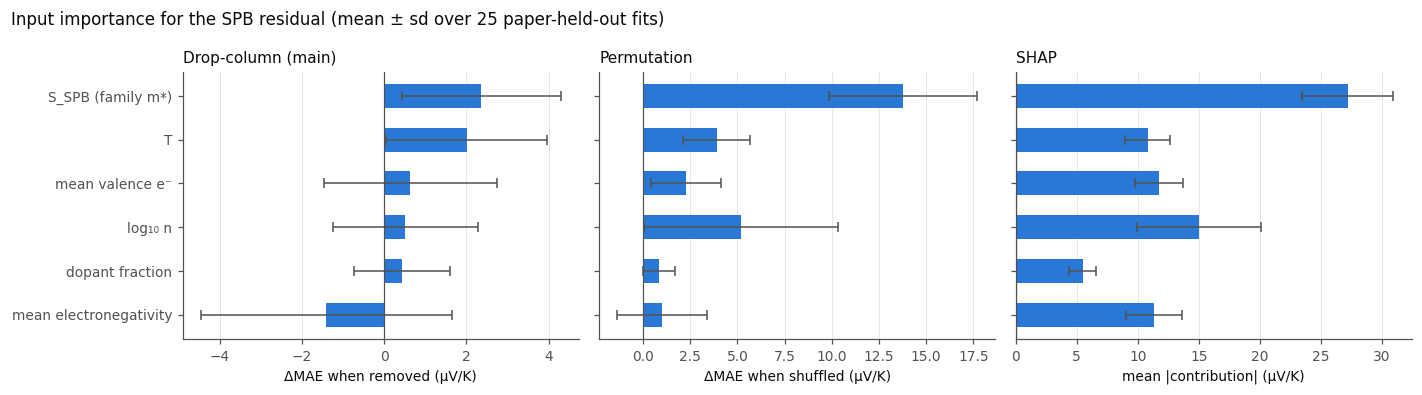

In [7]:
labels = {"T_K": "T", "log10_n_cm3": "log₁₀ n", "S_SPB": "S_SPB (family m*)", "el_X_mean": "mean electronegativity",
          "el_n_valence_mean": "mean valence e⁻", "dopant_total_frac": "dopant fraction"}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
order = agg.index[::-1]
for a, (col, sd, title, unit) in zip(ax, [("drop_column", "drop_column_sd", "Drop-column (main)", "ΔMAE when removed (µV/K)"),
                                         ("permutation", "permutation_sd", "Permutation", "ΔMAE when shuffled (µV/K)"),
                                         ("shap", "shap_sd", "SHAP", "mean |contribution| (µV/K)")]):
    y = np.arange(len(order))
    a.barh(y, agg.loc[order, col], xerr=agg.loc[order, sd], height=0.55, color=CAT[0],
           error_kw=dict(ecolor=INK2, lw=1, capsize=3))
    a.axvline(0, color=INK2, lw=0.8)
    a.set_yticks(y, [labels[i] for i in order]); a.set_title(title, loc="left", fontsize=10, color=INK)
    a.set_xlabel(unit); a.xaxis.grid(True, color=GRID, lw=0.6); a.set_axisbelow(True)
fig.suptitle(f"Input importance for the SPB residual (mean ± sd over {len(scores)} paper-held-out fits)",
             x=0.01, ha="left", fontsize=11, color=INK)
plt.tight_layout(); plt.savefig(OUT / "fig_input_ranking.png"); plt.show()

## Part B: merge families by XGBoost transferability
**Distance between groups A and B.** Let E(A→B) be the MAE on B of a model trained on A, and E*(B) be B's reference error:
the better of its own paper-grouped CV model and the calibrated SPB alone.

R(A→B) = E(A→B) / E*(B), and distance(A, B) = ½[R(A→B) + R(B→A)] − 1, floored at 0.

0 means each group's residual is predicted as well by the other's model as by its own, so they can share one model.
Groups: named families plus `[fallback]` classes with ≥ `MIN_GROUP_PAPERS` papers. Smaller groups stay out of the tree
and are always predicted by the pooled model.

In [8]:
def paper_folds(df, k, seed=0):
    sids = sorted(df.SID.unique(), key=lambda s: hashlib.sha256(f"{seed}-{s}".encode()).hexdigest())
    fmap = {s: i % k for i, s in enumerate(sids)}
    return df.SID.map(fmap).to_numpy()

def transfer_matrix(data):
    """data must contain residual column 'res'. Returns (distance df, R df, info df)."""
    cnt = data.groupby("group").agg(papers=("SID", "nunique"), points=("point_id", "size"))
    G = cnt[(cnt.papers >= MIN_GROUP_PAPERS) & (cnt.points >= MIN_GROUP_POINTS)].index.tolist()
    info, models = {}, {}
    for g in G:
        sub = data[data.group == g]
        pf = paper_folds(sub, min(SELF_FOLDS, sub.SID.nunique()))
        oof = np.zeros(len(sub))
        for kk in np.unique(pf):
            tr, te = pf != kk, pf == kk
            oof[te] = xgb_fit(sub[INPUTS][tr], sub.res[tr], sub.w[tr], XGB_SMALL).predict(sub[INPUTS][te])
        e_self, e_zero = mae(sub.res, oof), mae(sub.res, 0)
        info[g] = {"papers": sub.SID.nunique(), "points": len(sub), "E_own_model": e_self, "E_SPB_only": e_zero,
                   "E_ref": min(e_self, e_zero)}
        models[g] = xgb_fit(sub[INPUTS], sub.res, sub.w, XGB_SMALL)
    R = pd.DataFrame(1.0, index=G, columns=G)          # rows: trained on A, columns: evaluated on B
    for a in G:
        for b in G:
            if a != b:
                sub = data[data.group == b]
                R.loc[a, b] = mae(sub.res, models[a].predict(sub[INPUTS])) / info[b]["E_ref"]
    Dv = np.clip((R.values + R.values.T) / 2 - 1, 0, None); np.fill_diagonal(Dv, 0)
    D = pd.DataFrame(Dv, index=G, columns=G)
    return D, R, pd.DataFrame(info).T

def merge_groups(D, threshold=MERGE_THRESHOLD):
    Z = linkage(squareform(D.values, checks=False), method="average")
    lab = fcluster(Z, t=threshold, criterion="distance")
    return Z, dict(zip(D.index, lab))

### B1. Descriptive merge tree on ALL data (for understanding and the figure; **not** an evaluation)

In [9]:
t0 = time.time()
dd = d.copy(); dd["S_SPB"] = calibrate(dd)[0]; dd["res"] = dd.S_abs_uVK - dd.S_SPB
D_all, R_all, info_all = transfer_matrix(dd)
Z_all, lab_all = merge_groups(D_all)
print(f"{len(D_all)} groups in the tree ({time.time() - t0:.0f} s)")

# name merged clusters: multi-member clusters get M1, M2, ... ordered by size; singletons stay themselves
members = pd.DataFrame({"group": list(lab_all), "cl": list(lab_all.values())}).groupby("cl")["group"].apply(list)
size = {c: info_all.loc[m, "points"].sum() for c, m in members.items()}
multi = sorted([c for c, m in members.items() if len(m) > 1], key=lambda c: -size[c])
cl_name = {c: f"M{i + 1}" for i, c in enumerate(multi)}
cl_color = {c: (CAT[i] if i < len(CAT) else NEUTRAL) for i, c in enumerate(multi)}
merged_map = {g: (cl_name[lab_all[g]] if lab_all[g] in cl_name else g) for g in lab_all}
merge_table = (pd.DataFrame({"group": list(lab_all), "merged_group": [merged_map[g] for g in lab_all]})
                 .join(info_all, on="group").sort_values(["merged_group", "points"], ascending=[True, False]))
display(merge_table.round(2))
for c in multi:
    print(f"{cl_name[c]}: " + " + ".join(members[c]))

26 groups in the tree (8 s)


,group,merged_group,papers,points,E_own_model,E_SPB_only,E_ref
0,Anti-La2O3 Mg3Pn2 Zintl,Anti-La2O3 Mg3Pn2 Zintl,5.0,145.0,57.35,19.89,19.89
6,Half-Heusler XYZ,Half-Heusler XYZ,11.0,219.0,42.69,56.08,42.69
2,Bi-Sb alloy (semimetal),M1,7.0,577.0,32.36,31.20,31.20
4,Chalcopyrite I-III-VI2,M1,9.0,480.0,49.84,58.11,49.84
24,[fallback] Telluride,M1,27.0,477.0,105.88,83.32,83.32
12,Rock-salt PbQ,M1,17.0,386.0,52.58,40.56,40.56
19,Zn-Sb (ZnSb / Zn4Sb3),M1,4.0,221.0,59.27,45.72,45.72
3,CaAl2Si2-type AM2Pn2 Zintl,M1,6.0,168.0,33.66,28.51,28.51
20,"ZrBeSi/LiGaGe-type ABPn (BaAgSb, EuCuSb)",M1,5.0,136.0,37.96,27.52,27.52
5,Diamond-like I2-IV-VI3 (Cu2SnSe3-type),M1,5.0,90.0,63.57,58.92,58.92


M1: Bi-Sb alloy (semimetal) + CaAl2Si2-type AM2Pn2 Zintl + Chalcopyrite I-III-VI2 + Diamond-like I2-IV-VI3 (Cu2SnSe3-type) + I-V-VI2 rock-salt (AgSbTe2-type) + Rock-salt PbQ + Zintl chain/ribbon antimonides (A9M4Pn9, A5M2Pn6, A3MPn3) + Zn-Sb (ZnSb / Zn4Sb3) + ZrBeSi/LiGaGe-type ABPn (BaAgSb, EuCuSb) + [fallback] Telluride
M2: Antifluorite/superionic M2Q (Cu2Se-type) + Layered SnQ (SnSe/SnS, Pnma) + [fallback] Intermetallic (rare-earth / actinide) + [fallback] Selenide
M3: Skutterudite MPn3 + [fallback] Oxide
M4: Perovskite SrTiO3 + Rhombohedral GeTe
M5: Si-Ge alloy (diamond) + Wurtzite ZnO


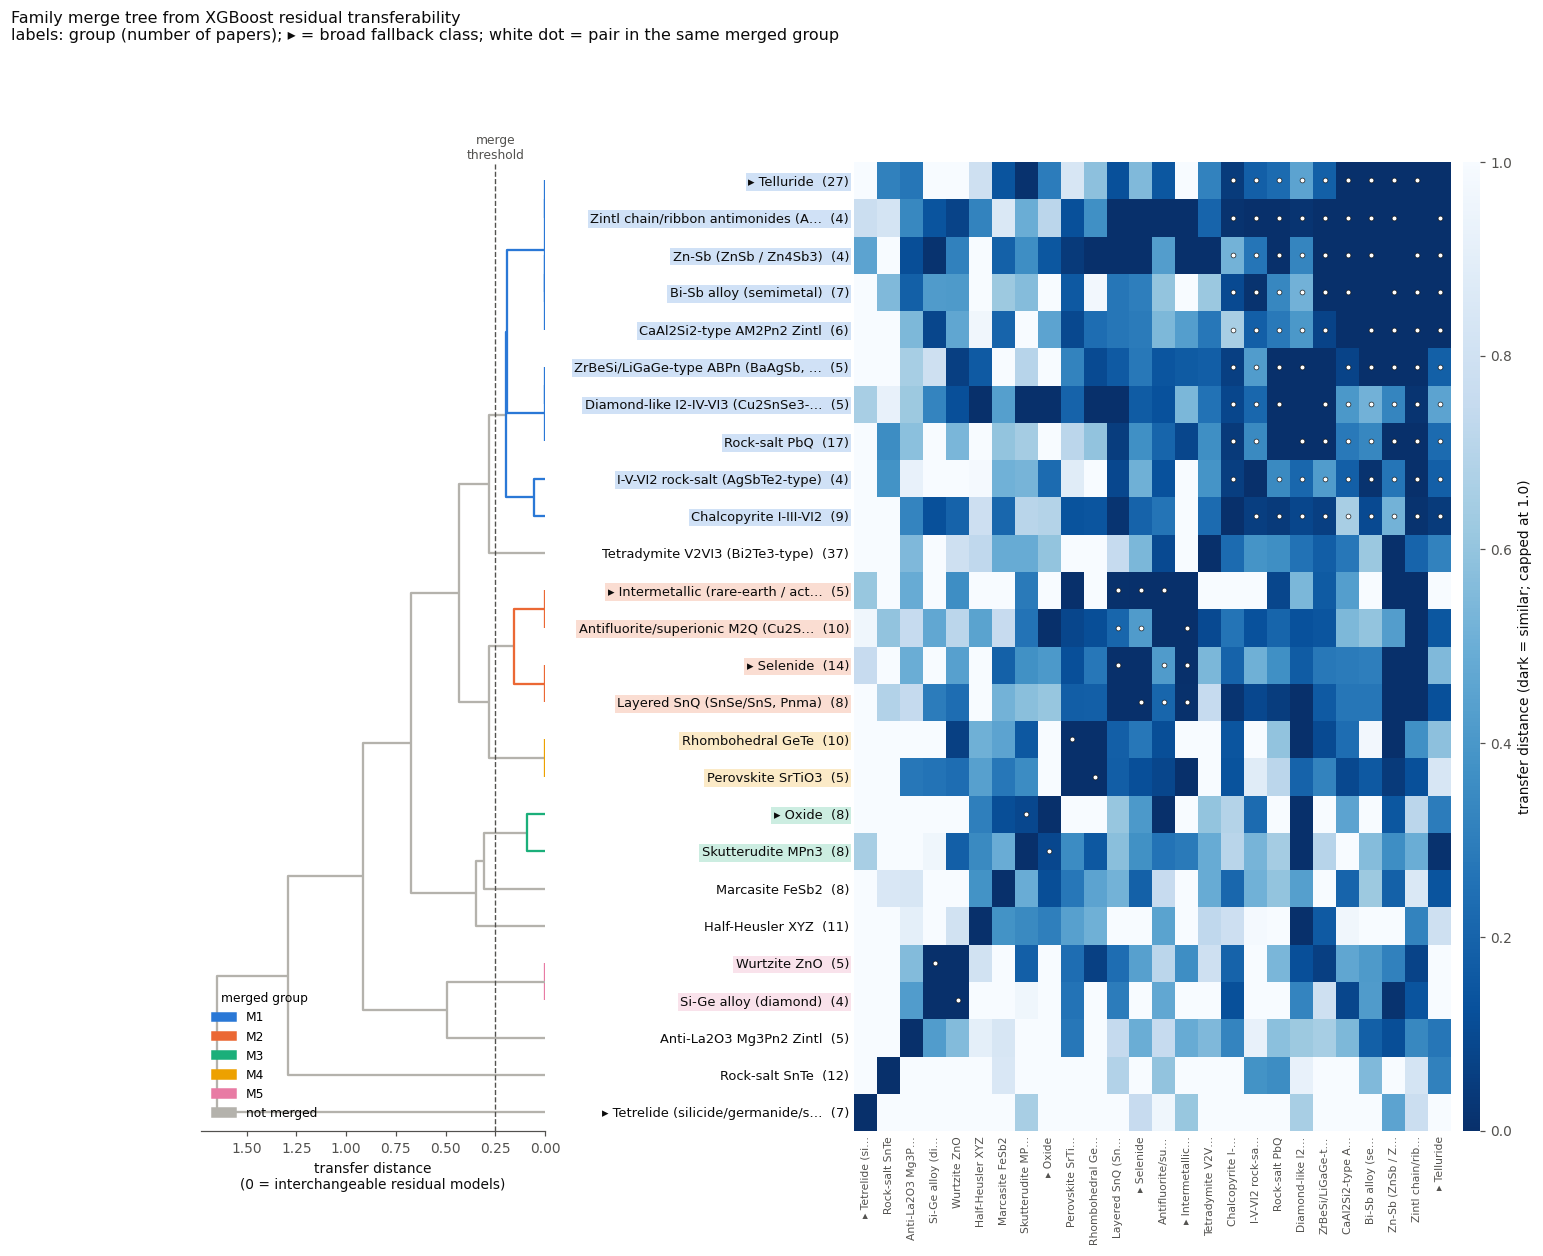

In [10]:
def short(g, n=34):
    g = g.replace("[fallback] ", "▸ ")
    return g if len(g) <= n else g[:n - 1] + "…"

# ---- Figure: merge tree (dendrogram) + transfer-distance heatmap -------------------------
leaf_color = {g: cl_color.get(lab_all[g], NEUTRAL) for g in D_all.index}
def link_color(i, Z=Z_all, G=list(D_all.index)):
    n = len(G)
    def leaves(j):
        return [int(j)] if j < n else leaves(Z[int(j) - n, 0]) + leaves(Z[int(j) - n, 1])
    cols = {leaf_color[G[l]] for l in leaves(i)}
    return cols.pop() if len(cols) == 1 else NEUTRAL

n_g = len(D_all)
fig = plt.figure(figsize=(15, 0.34 * n_g + 2.6))
gs = fig.add_gridspec(1, 4, width_ratios=[0.75, 0.62, 1.3, 0.035], wspace=0.04)
ax_d = fig.add_subplot(gs[0]); ax_h = fig.add_subplot(gs[2]); ax_c = fig.add_subplot(gs[3])   # gs[1] = label space
dn = dendrogram(Z_all, orientation="left", no_labels=True, ax=ax_d, link_color_func=link_color)
leaves_bt = [D_all.index[i] for i in dn["leaves"]]           # bottom -> top
ax_d.set_ylim(0, 10 * n_g)
ax_d.axvline(MERGE_THRESHOLD, color=INK2, ls="--", lw=0.9)
ax_d.text(MERGE_THRESHOLD, 10 * n_g, "merge\nthreshold", color=INK2, fontsize=8, va="bottom", ha="center")
ax_d.set_xlabel("transfer distance\n(0 = interchangeable residual models)")
ax_d.set_yticks([]); ax_d.spines["left"].set_visible(False)
M = D_all.loc[leaves_bt, leaves_bt].values
VMAX = 1.0
im = ax_h.imshow(np.minimum(M, VMAX), cmap="Blues_r", vmin=0, vmax=VMAX, aspect="auto", origin="lower",
                 extent=(-0.5, n_g - 0.5, -0.5, n_g - 0.5))
same = np.array([[lab_all[a] == lab_all[b] and a != b for b in leaves_bt] for a in leaves_bt])
ii, jj = np.where(same)
ax_h.scatter(jj, ii, s=10, color="white", edgecolor=INK, linewidth=0.4, zorder=3)
ax_h.set_yticks(range(n_g), [f"{short(g)}  ({int(info_all.loc[g, 'papers'])})" for g in leaves_bt], fontsize=8.5)
ax_h.set_xticks(range(n_g), [short(g, 16) for g in leaves_bt], rotation=90, fontsize=7)
for tick, g in zip(ax_h.get_yticklabels(), leaves_bt):
    tick.set_color(INK)
    if leaf_color[g] != NEUTRAL:
        tick.set_bbox(dict(facecolor=leaf_color[g], alpha=0.22, edgecolor="none", pad=1.5))
ax_h.tick_params(length=0); [s_.set_visible(False) for s_ in ax_h.spines.values()]
cb = fig.colorbar(im, cax=ax_c); cb.set_label(f"transfer distance (dark = similar; capped at {VMAX})"); cb.outline.set_visible(False)
handles = [mpatches.Patch(color=cl_color[c], label=cl_name[c]) for c in multi] + [mpatches.Patch(color=NEUTRAL, label="not merged")]
ax_d.legend(handles=handles, loc="lower left", frameon=False, fontsize=8, title="merged group", title_fontsize=8)
fig.suptitle("Family merge tree from XGBoost residual transferability\n"
             "labels: group (number of papers); ▸ = broad fallback class; white dot = pair in the same merged group",
             x=0.01, ha="left", fontsize=10.5, color=INK, y=1.0)
plt.savefig(OUT / "fig_family_merge_tree.png"); plt.show()

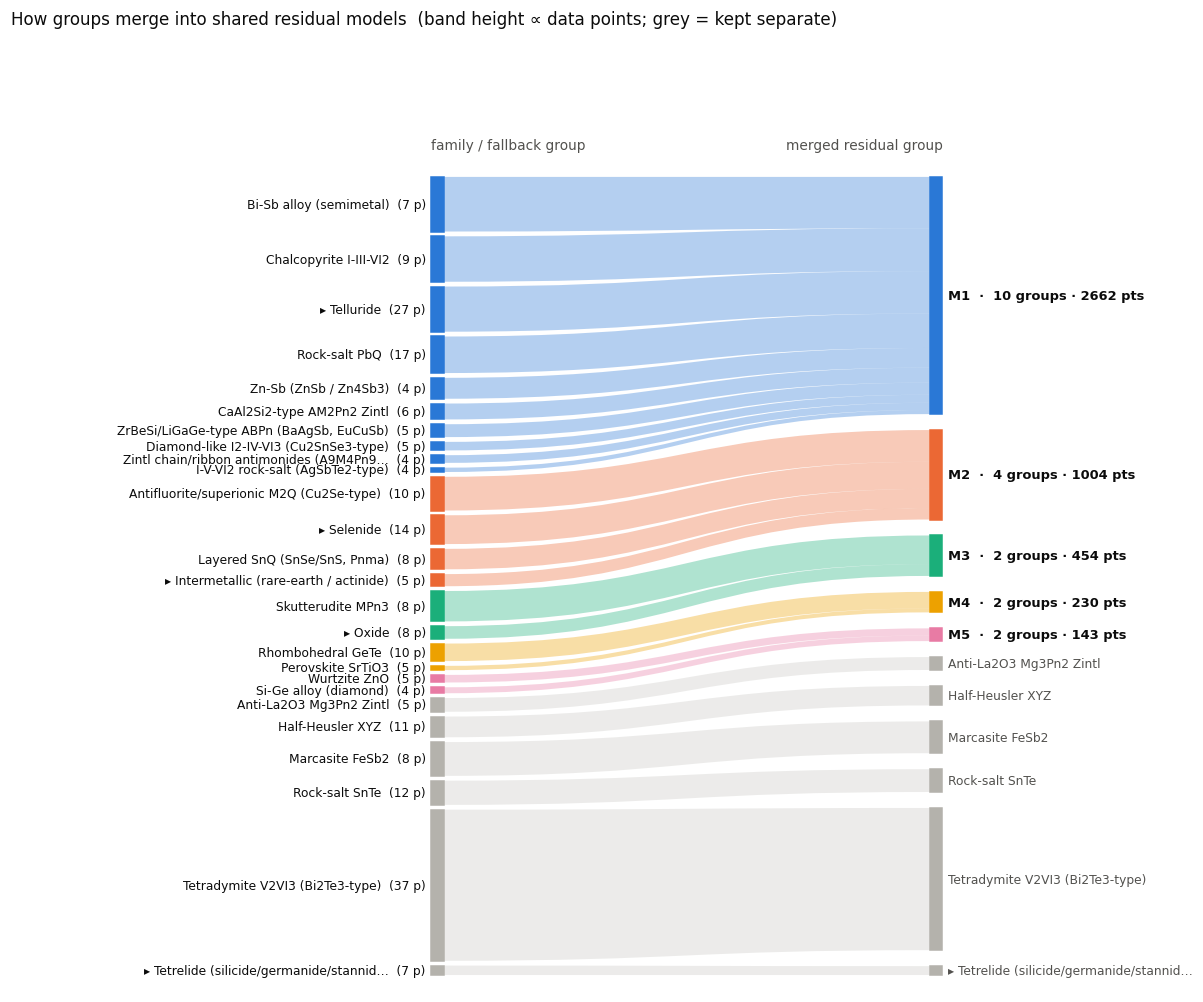

In [11]:
# ---- Figure: alluvial flow, families -> merged groups ------------------------------------
def alluvial(merge_table, info, fname):
    mt = merge_table.copy()
    rights = [cl_name[c] for c in multi] + [g for g in mt.merged_group.unique() if g not in cl_name.values()]
    left = (mt.assign(_r=mt.merged_group.map({r: i for i, r in enumerate(rights)}))
              .sort_values(["_r", "points"], ascending=[True, False]))
    gap, H = 0.006, 1.0
    tot = mt.points.sum(); scale = (H - gap * (len(mt) - 1)) / tot
    y, lpos = H, {}
    for g, p_ in zip(left.group, left.points):
        h = p_ * scale; lpos[g] = (y - h, y); y -= h + gap
    rtot = mt.groupby("merged_group").points.sum()
    gap_r = 0.02; scale_r = (H - gap_r * (len(rights) - 1)) / tot
    y, rpos = H, {}
    for r in rights:
        h = rtot[r] * scale_r; rpos[r] = [y - h, y, y]; y -= h + gap_r   # [bottom, top, fill cursor]
    fig, ax = plt.subplots(figsize=(12, 0.3 * len(mt) + 2))
    xl, xr, w = 0.0, 1.0, 0.025
    colr = lambda r: next((cl_color[c] for c in multi if cl_name[c] == r), NEUTRAL)
    for g, p_ in zip(left.group, left.points):
        r = mt.set_index("group").loc[g, "merged_group"]; c = colr(r)
        l0, l1 = lpos[g]; h = p_ * scale_r; r1 = rpos[r][2]; r0 = r1 - h; rpos[r][2] = r0
        verts = [(xl + w, l1), (0.5, l1), (0.5, r1), (xr - w, r1), (xr - w, r0), (0.5, r0), (0.5, l0), (xl + w, l0), (xl + w, l1)]
        codes = [MPath.MOVETO, MPath.CURVE4, MPath.CURVE4, MPath.CURVE4, MPath.LINETO, MPath.CURVE4, MPath.CURVE4, MPath.CURVE4, MPath.CLOSEPOLY]
        ax.add_patch(mpatches.PathPatch(MPath(verts, codes), facecolor=c, edgecolor="none", alpha=0.35 if c != NEUTRAL else 0.25))
        ax.add_patch(mpatches.Rectangle((xl, l0), w, l1 - l0, color=c))
        ax.text(xl - 0.01, (l0 + l1) / 2, f"{short(g, 40)}  ({int(info.loc[g, 'papers'])} p)", ha="right", va="center", fontsize=8, color=INK)
    for r in rights:
        b, t_, _ = rpos[r]; c = colr(r)
        ax.add_patch(mpatches.Rectangle((xr - w, b), w, t_ - b, color=c))
        n_mem = (mt.merged_group == r).sum()
        lab = f"{r}  ·  {n_mem} groups · {int(rtot[r])} pts" if n_mem > 1 else short(r, 40)
        ax.text(xr + 0.01, (b + t_) / 2, lab, ha="left", va="center", fontsize=8.5 if n_mem > 1 else 8,
                color=INK if n_mem > 1 else INK2, fontweight="bold" if n_mem > 1 else "normal")
    ax.set_xlim(-0.55, 1.45); ax.set_ylim(-0.02, 1.02); ax.axis("off")
    ax.text(xl, 1.035, "family / fallback group", fontsize=9, color=INK2, ha="left")
    ax.text(xr, 1.035, "merged residual group", fontsize=9, color=INK2, ha="right")
    fig.suptitle("How groups merge into shared residual models  (band height ∝ data points; grey = kept separate)",
                 x=0.02, ha="left", fontsize=11, color=INK, y=1.02)
    plt.savefig(OUT / fname); plt.show()
alluvial(merge_table, info_all, "fig_family_merge_flow.png")

### B2. Is merging actually better? Nested, leakage-free validation (primary split)
For each outer fold: m* is calibrated on the training papers, the **transfer matrix and merge tree are rebuilt from the
training papers only**, and four residual strategies are trained and scored on the held-out papers:

| Strategy | Residual model |
|---|---|
| SPB (family m*) | none (residual = 0) |
| Per-family | one XGBoost per eligible group; everything else uses the pooled model |
| **Merged** | one XGBoost per merged group (from this fold's tree); everything else uses the pooled model |
| Pooled | one XGBoost for all training data |

We also record how often each pair of groups merges across the outer folds. Pairs that merge in every fold are a stable result.

outer fold 0: 23 groups, 8 after merging (8 s)
outer fold 1: 20 groups, 8 after merging (17 s)
outer fold 2: 21 groups, 8 after merging (28 s)
outer fold 3: 21 groups, 9 after merging (35 s)
outer fold 4: 20 groups, 9 after merging (44 s)


,MAE (µV/K),RMSE (µV/K)
SPB (family m*) only,68.06,102.16
SPB + per-family XGB,60.63,92.33
SPB + merged-group XGB,59.34,90.55
SPB + one pooled XGB,57.13,88.68


,papers,SPB (family m*) only,SPB + per-family XGB,SPB + merged-group XGB,SPB + one pooled XGB
group,,,,,
Tetradymite V2VI3 (Bi2Te3-type),37,63.7,61.8,61.8,60.1
[fallback] Telluride,27,81.4,83.6,68.7,63.8
Rock-salt PbQ,17,42.1,49.4,57.4,42.2
[fallback] Selenide,14,47.5,42.1,54.0,51.5
Rock-salt SnTe,12,73.5,23.0,23.7,28.3
Half-Heusler XYZ,11,58.2,53.8,42.3,58.4
Rhombohedral GeTe,10,36.4,39.3,46.8,31.4
Antifluorite/superionic M2Q (Cu2Se-type),10,58.8,91.2,75.2,48.7
Chalcopyrite I-III-VI2,9,58.7,45.6,45.9,53.0


Pairs present together in >= 3 outer folds and merged in >= 60 % of them:


,group A,group B,folds both present,share merged
5,Chalcopyrite I-III-VI2,"Layered SnQ (SnSe/SnS, Pnma)",4,1.000000
0,Anti-La2O3 Mg3Pn2 Zintl,Bi-Sb alloy (semimetal),3,1.000000
12,Rock-salt PbQ,"ZrBeSi/LiGaGe-type ABPn (BaAgSb, EuCuSb)",3,1.000000
6,Chalcopyrite I-III-VI2,Rock-salt PbQ,5,0.800000
9,"Layered SnQ (SnSe/SnS, Pnma)",Rock-salt PbQ,4,0.750000
1,Bi-Sb alloy (semimetal),"ZrBeSi/LiGaGe-type ABPn (BaAgSb, EuCuSb)",3,0.666667
2,CaAl2Si2-type AM2Pn2 Zintl,Perovskite SrTiO3,3,0.666667
3,CaAl2Si2-type AM2Pn2 Zintl,Wurtzite ZnO,3,0.666667
4,Chalcopyrite I-III-VI2,Diamond-like I2-IV-VI3 (Cu2SnSe3-type),3,0.666667
7,Chalcopyrite I-III-VI2,"ZrBeSi/LiGaGe-type ABPn (BaAgSb, EuCuSb)",3,0.666667


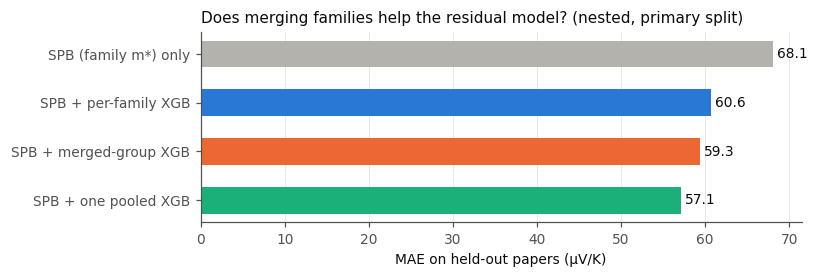

In [12]:
if NESTED:
    t0 = time.time()
    preds = {k_: np.full(len(d), np.nan) for k_ in ["SPB", "per_family", "merged", "pooled"]}
    comerge = []
    for k, (tr, te) in enumerate(splits_from(d["fold"])):
        train, test = d.iloc[tr].copy(), d.iloc[te].copy()
        train["S_SPB"], test["S_SPB"] = calibrate(train, test)
        train["res"] = train.S_abs_uVK - train.S_SPB
        D_k, _, info_k = transfer_matrix(train)
        _, lab_k = merge_groups(D_k)
        comerge.append(lab_k)
        pooled = xgb_fit(train[INPUTS], train.res, train.w)
        p_pool = pooled.predict(test[INPUTS])
        p_fam, p_mrg = p_pool.copy(), p_pool.copy()
        for g in D_k.index:                                   # per-family
            mtr, mte = train.group == g, (test.group == g).to_numpy()
            if mte.any():
                p_fam[mte] = xgb_fit(train[INPUTS][mtr], train.res[mtr], train.w[mtr], XGB_SMALL).predict(test[INPUTS][mte])
        for c in set(lab_k.values()):                         # merged
            gs_ = [g for g in lab_k if lab_k[g] == c]
            mtr, mte = train.group.isin(gs_), test.group.isin(gs_).to_numpy()
            if mte.any():
                prm = XGB_PARAMS if len(gs_) > 1 else XGB_SMALL
                p_mrg[mte] = xgb_fit(train[INPUTS][mtr], train.res[mtr], train.w[mtr], prm).predict(test[INPUTS][mte])
        preds["SPB"][te] = test.S_SPB; preds["pooled"][te] = test.S_SPB + p_pool
        preds["per_family"][te] = test.S_SPB + p_fam; preds["merged"][te] = test.S_SPB + p_mrg
        print(f"outer fold {k}: {len(D_k)} groups, {len(set(lab_k.values()))} after merging ({time.time() - t0:.0f} s)")
    names = {"SPB": "SPB (family m*) only", "per_family": "SPB + per-family XGB", "merged": "SPB + merged-group XGB",
             "pooled": "SPB + one pooled XGB"}
    nest = pd.DataFrame({names[k_]: {"MAE (µV/K)": mae(d.S_abs_uVK, v), "RMSE (µV/K)": rmse(d.S_abs_uVK, v)} for k_, v in preds.items()}).T
    display(nest.round(2))
    by_g = pd.DataFrame([{"group": g, "papers": gg.SID.nunique(), **{names[k_]: mae(gg.S_abs_uVK, preds[k_][gg.index]) for k_ in preds}}
                         for g, gg in d.groupby("group")]).set_index("group").sort_values("papers", ascending=False)
    display(by_g.round(1))
    # co-merge stability
    allg = sorted(set().union(*[set(c) for c in comerge]))
    CM = pd.DataFrame(0.0, index=allg, columns=allg); CN = CM.copy()
    for lab_k in comerge:
        for a in lab_k:
            for b in lab_k:
                CN.loc[a, b] += 1; CM.loc[a, b] += lab_k[a] == lab_k[b]
    stab = (CM / CN.replace(0, np.nan))
    pairs = [(a, b, int(CN.loc[a, b]), stab.loc[a, b]) for i, a in enumerate(allg) for b in allg[i + 1:]
             if CN.loc[a, b] >= 3 and stab.loc[a, b] >= 0.6]
    print("Pairs present together in >= 3 outer folds and merged in >= 60 % of them:")
    display(pd.DataFrame(pairs, columns=["group A", "group B", "folds both present", "share merged"])
              .sort_values(["share merged", "folds both present"], ascending=False))

    fig, ax = plt.subplots(figsize=(7.5, 2.6))
    y = np.arange(len(nest))[::-1]
    cols = [NEUTRAL, CAT[0], CAT[1], CAT[2]]
    ax.barh(y, nest["MAE (µV/K)"], color=cols, height=0.55)
    for yi, v in zip(y, nest["MAE (µV/K)"]):
        ax.text(v + 0.5, yi, f"{v:.1f}", va="center", fontsize=9, color=INK)
    ax.set_yticks(y, nest.index); ax.set_xlabel("MAE on held-out papers (µV/K)")
    ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.set_title("Does merging families help the residual model? (nested, primary split)", loc="left", fontsize=10, color=INK)
    plt.tight_layout(); plt.savefig(OUT / "fig_merge_validation.png"); plt.show()

## Save
- `input_ranking.csv` (aggregated) and `input_importance_per_fit.csv`; `model_scores_per_fit.csv`
- `transfer_distance_alldata.csv`, `transfer_ratio_alldata.csv`, `merge_table_alldata.csv` (descriptive)
- `features_with_merged_groups.csv`: the input file plus `merged_group` (descriptive, all-data tree). **For evaluation,
  rebuild the tree inside the training folds, as in B2.**
- `nested_merge_validation.csv`, `nested_by_group.csv`, `comerge_stability.csv`
- figures: `fig_input_ranking.png`, `fig_family_merge_tree.png`, `fig_family_merge_flow.png`, `fig_merge_validation.png`

In [13]:
agg.to_csv(OUT / "input_ranking.csv"); imp.to_csv(OUT / "input_importance_per_fit.csv", index=False)
scores.to_csv(OUT / "model_scores_per_fit.csv", index=False)
D_all.to_csv(OUT / "transfer_distance_alldata.csv"); R_all.to_csv(OUT / "transfer_ratio_alldata.csv")
merge_table.to_csv(OUT / "merge_table_alldata.csv", index=False)
d.assign(merged_group=d.group.map(merged_map).fillna("pooled (small group)")).drop(columns=["n_m3", "w"]) \
 .to_csv(OUT / "features_with_merged_groups.csv", index=False)
if NESTED:
    nest.to_csv(OUT / "nested_merge_validation.csv"); by_g.to_csv(OUT / "nested_by_group.csv"); stab.to_csv(OUT / "comerge_stability.csv")
report = {"settings": {"INPUTS": INPUTS, "EXCLUDE_FAMILIES": EXCLUDE_FAMILIES, "RANK_SEEDS": RANK_SEEDS, "XGB_PARAMS": XGB_PARAMS,
                       "MERGE_THRESHOLD": MERGE_THRESHOLD, "MIN_GROUP_PAPERS": MIN_GROUP_PAPERS, "SELF_FOLDS": SELF_FOLDS,
                       "xgboost_version": xgb.__version__},
          "ranking_dropcol_dMAE": agg["drop_column"].round(3).to_dict(),
          "scores_mean_over_seeds": s.mean().round(2).to_dict(),
          "merged_groups_alldata": {cl_name[c]: members[c] for c in multi},
          "nested": nest.round(2).to_dict() if NESTED else None}
(OUT / "xgb_report.json").write_text(json.dumps(report, indent=2, default=float))
import shutil
shutil.make_archive("xgb_ranking_merging", "zip", OUT)
try:
    from google.colab import files
    files.download("xgb_ranking_merging.zip")
except ImportError:
    print("zip at xgb_ranking_merging.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>